In [1]:
import pandas as pd


df_train = pd.read_csv("../data/train.csv")
df_test = pd.read_csv("../data/test.csv")

# 'Unnamed: 0' is the old row index saved by to_csv(). In train.csv the oversampled
# churn rows sit at the end, so the index leaks the label -> drop it.
for d in (df_train, df_test):
    d.drop(columns=d.columns[d.columns.str.startswith("Unnamed")], inplace=True)

ytrain= df_train["Churn"]
xtrain = df_train.drop(columns=["Churn"])
ytest= df_test["Churn"]
xtest = df_test.drop(columns=["Churn"])


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , classification_report
model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42)
model.fit(xtrain, ytrain)
y_pred = model.predict(xtest)

print("Accuracy:", accuracy_score(ytest, y_pred))
print(classification_report(ytest, y_pred))
print("Feature importances:", model.feature_importances_)

Accuracy: 0.7643718949609652
              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.54      0.70      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409

Feature importances: [0.00718132 0.11071156 0.07270372 0.09191941 0.0128534  0.02502465
 0.04799707 0.00432973 0.00456166 0.00650765 0.04215222 0.01608468
 0.01932842 0.08669191 0.01397796 0.03520566 0.01692463 0.01788913
 0.02777718 0.06890863 0.01360165 0.00634067 0.01561108 0.00602627
 0.06229966 0.10598084 0.00813535 0.02825006 0.00746584 0.01755801]


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score , classification_report

import joblib

model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
model.fit(xtrain, ytrain)
y_pred = model.predict(xtest)

print("Accuracy:", accuracy_score(ytest, y_pred))
print(classification_report(ytest, y_pred))


# Save model to file
joblib.dump(model, '../model/model.pkl')
print("Model saved successfully!")

Accuracy: 0.7629524485450674
              precision    recall  f1-score   support

           0       0.86      0.81      0.83      1035
           1       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409

Model saved successfully!


: 

## Compare all classifiers on the test set

In [12]:
import time
import warnings
import numpy as np
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier, Perceptron
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              AdaBoostClassifier, BaggingClassifier)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

# Scale-sensitive models get a StandardScaler; tree models don't need one.
def scaled(est):
    return make_pipeline(StandardScaler(), est)

models = {
    "Logistic Regression":     scaled(LogisticRegression(max_iter=2000)),
    "Ridge Classifier":        scaled(RidgeClassifier()),
    "SGD Classifier":          scaled(SGDClassifier(random_state=42)),
    "Perceptron":              scaled(Perceptron(random_state=42)),
    "Linear SVC":              scaled(LinearSVC(max_iter=5000, random_state=42)),
    "SVC (RBF)":               scaled(SVC(kernel="rbf", C=1.0, gamma="scale")),
    "KNN":                     scaled(KNeighborsClassifier(n_neighbors=15)),
    "Gaussian NB":             GaussianNB(),
    "Bernoulli NB":            BernoulliNB(),
    "LDA":                     LinearDiscriminantAnalysis(),
    "QDA":                     QuadraticDiscriminantAnalysis(reg_param=0.1),  # reg_param: one-hot columns are collinear
    "Decision Tree":           DecisionTreeClassifier(max_depth=8, random_state=42),
    "Extra Tree":              ExtraTreeClassifier(max_depth=8, random_state=42),
    "Random Forest":           RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42),
    "Extra Trees":             ExtraTreesClassifier(n_estimators=300, max_depth=10, random_state=42),
    "Gradient Boosting":       GradientBoostingClassifier(random_state=42),
    "HistGradient Boosting":   HistGradientBoostingClassifier(random_state=42),
    "AdaBoost":                AdaBoostClassifier(random_state=42),
    "Bagging":                 BaggingClassifier(n_estimators=100, random_state=42),
    "MLP (Neural Net)":        scaled(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)),
}

# Optional libraries: only added if installed (pip install xgboost lightgbm catboost)
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                                      eval_metric="logloss", random_state=42)
except ImportError:
    print("xgboost not installed - skipped")
try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
except ImportError:
    print("lightgbm not installed - skipped")
try:
    from catboost import CatBoostClassifier
    models["CatBoost"] = CatBoostClassifier(iterations=300, learning_rate=0.05, random_state=42, verbose=0)
except ImportError:
    print("catboost not installed - skipped")


def get_scores(model, X):
    """Continuous score for ROC-AUC (probability if available, else decision function)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return None


results, fitted = [], {}
for name, est in models.items():
    est = clone(est)
    try:
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            est.fit(xtrain, ytrain)
            y_pred = est.predict(xtest)
            scores = get_scores(est, xtest)
        results.append({
            "Model": name,
            "Accuracy":  accuracy_score(ytest, y_pred),
            "Precision": precision_score(ytest, y_pred, zero_division=0),
            "Recall":    recall_score(ytest, y_pred),
            "F1":        f1_score(ytest, y_pred),
            "ROC-AUC":   roc_auc_score(ytest, scores) if scores is not None else np.nan,
            "Time (s)":  time.time() - t0,
        })
        fitted[name] = est
    except Exception as e:
        print(f"{name} failed: {e}")

# Precision / Recall / F1 are for the churn class (label 1)
results_df = (pd.DataFrame(results)
              .sort_values("F1", ascending=False)
              .reset_index(drop=True))
results_df.style.format({c: "{:.3f}" for c in results_df.columns if c not in ("Model", "Time (s)")}
                        | {"Time (s)": "{:.2f}"}).background_gradient(
    subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"], cmap="Greens")

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Time (s)
0,Linear SVC,0.782,0.578,0.663,0.618,0.834,0.12
1,Logistic Regression,0.783,0.581,0.655,0.616,0.835,0.10
2,Ridge Classifier,0.770,0.554,0.690,0.614,0.825,0.06
3,LDA,0.770,0.554,0.690,0.614,0.825,0.06
4,Random Forest,0.764,0.544,0.698,0.611,0.830,3.04
5,AdaBoost,0.757,0.532,0.717,0.610,0.828,0.58
6,Gradient Boosting,0.768,0.551,0.674,0.606,0.832,1.96
7,LightGBM,0.784,0.586,0.628,0.606,0.829,0.64
8,QDA,0.725,0.489,0.783,0.602,0.828,0.05
9,XGBoost,0.775,0.568,0.639,0.601,0.832,1.26


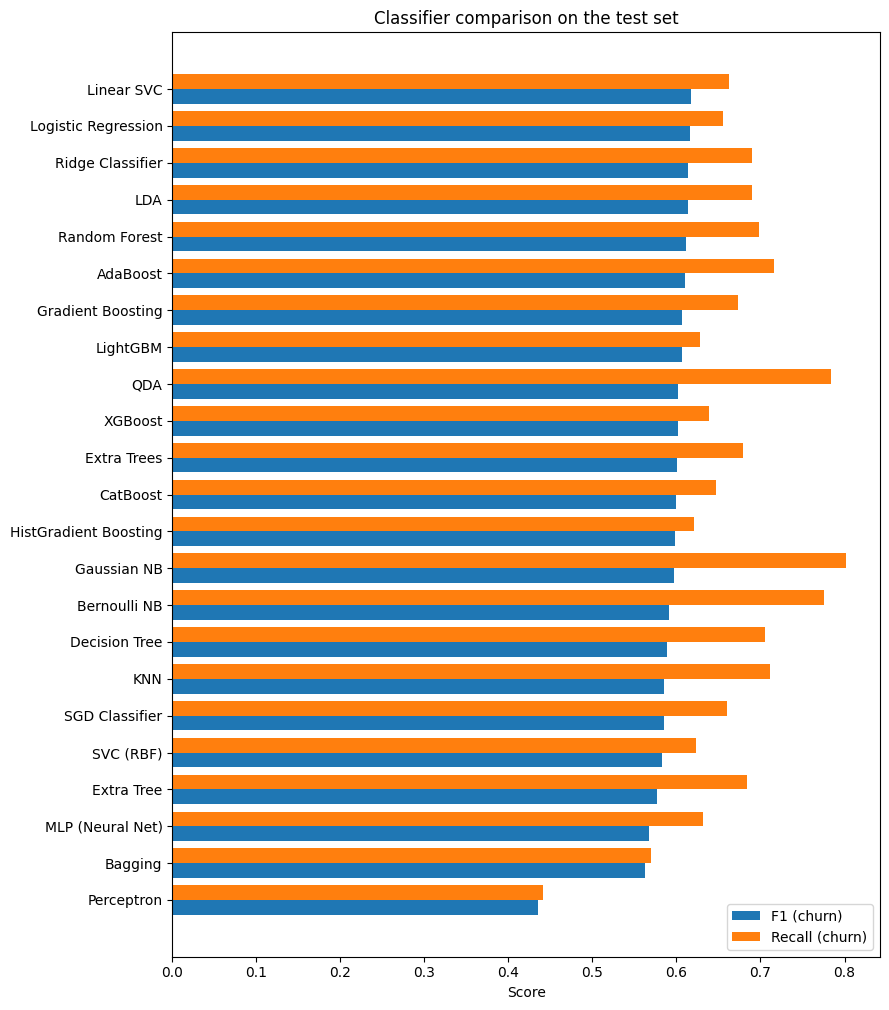

Best by F1: Linear SVC  (F1=0.618, Recall=0.663, ROC-AUC=0.834)


In [13]:
import matplotlib.pyplot as plt

plot_df = results_df.sort_values("F1")
fig, ax = plt.subplots(figsize=(9, 0.4 * len(plot_df) + 1))
y = np.arange(len(plot_df))
ax.barh(y - 0.2, plot_df["F1"], height=0.4, label="F1 (churn)")
ax.barh(y + 0.2, plot_df["Recall"], height=0.4, label="Recall (churn)")
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Model"])
ax.set_xlabel("Score")
ax.set_title("Classifier comparison on the test set")
ax.legend()
plt.tight_layout()
plt.show()

best = results_df.iloc[0]
print(f"Best by F1: {best['Model']}  (F1={best['F1']:.3f}, Recall={best['Recall']:.3f}, ROC-AUC={best['ROC-AUC']:.3f})")